# detection 패키지 코드 설명

`detection` 은 시계열에서 이상치를 찾는 패키지입니다. 알고리즘을 고르지 않고 6개를 전부 돌려 결과를 CSV로 내놓습니다.

이 노트북은 그 코드가 어떻게 돌아가는지 보여줍니다. 함수 13개는 코드를 직접 띄워 설명하고, 나머지는 표에 한 줄씩 정리했습니다.

데이터는 `data/전처리 데이터/입도 관광객 추이(일별).csv` 를 씁니다. 2013년 1월 1일부터 2026년 9월 2일까지 제주 입도 관광객 수가 하루에 한 줄씩 들어 있습니다.

## 0. 준비

이 노트북은 `detection/notebooks/` 안에 있습니다. `import detection` 이 되려면 저장소 뿌리가 `sys.path` 에 있어야 해서, 아래 셀에서 뿌리를 찾아 넣습니다. `detection/__init__.py` 가 있는 폴더를 위로 올라가며 찾으므로 어느 위치에서 열어도 돌아갑니다.

필요한 패키지는 pandas, numpy, scipy, statsmodels, matplotlib 입니다.

```
pip install pandas numpy scipy statsmodels matplotlib
```

In [1]:
import sys
from pathlib import Path

# 저장소 뿌리를 찾아 sys.path 에 넣는다 (detection 패키지가 있는 폴더)
여기 = Path.cwd()
뿌리 = next(p for p in [여기, *여기.parents]
            if (p / "detection" / "__init__.py").exists())
if str(뿌리) not in sys.path:
    sys.path.insert(0, str(뿌리))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from detection import load, run
from detection.common import (cannot_judge, drop_missing, empty_result, mad,
                              make_result, robust_standardize, standardize)
from detection.extreme import iqr, zscore
from detection.loader import (PRESETS, load_long, load_single, load_wide,
                              read_csv)
from detection.registry import ALGORITHMS, NEEDS_PERIOD, catalog
from detection.runner import COLUMNS, detect_all, detect_one, save, summarize
from detection.shape import skew_kurtosis
from detection.trend import stl_residual

plt.rcParams["font.family"] = "Malgun Gothic"   # 그래프 한글
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (11, 3.5)

DATA = 뿌리 / "data" / "전처리 데이터" / "입도 관광객 추이(일별).csv"
OUT = Path("out") / "code_explain"      # notebooks/out 은 .gitignore 에 들어 있다

print("뿌리  :", 뿌리.name)      # 집 폴더 경로가 노트북에 남지 않게 이름만
print("데이터:", DATA.name, "— 있나:", DATA.exists())
print("pandas", pd.__version__, "/ numpy", np.__version__)

뿌리  : tour-anomaly-benchmark
데이터: 입도 관광객 추이(일별).csv — 있나: True
pandas 2.2.3 / numpy 2.1.3


## 1. 전체 그림

데이터는 세 단계를 지납니다.

```
CSV 파일  →  loader.py  →  그룹 × 시점 표  →  알고리즘 6개  →  anomalies.csv
```

`loader.py` 가 형식이 다른 CSV를 표 하나로 바꿉니다. 행은 분석 단위(격자, 지역, 지표), 열은 시점입니다. 이 표만 만들어지면 알고리즘은 숫자 한 줄만 받으면 됩니다.

`runner.py` 가 표의 행마다 알고리즘 6개를 전부 돌립니다. 어느 알고리즘 결과를 쓸지는 고르지 않습니다. 전부 CSV에 담고 받는 쪽이 정합니다.

### 함수 25개

`설명` 칸에 표시가 있는 함수는 이 노트북에서 코드를 띄워 설명합니다.

| 파일 | 함수 | 하는 일 | 설명 |
|---|---|---|---|
| loader.py | `read_csv` | 인코딩을 차례로 시도해 CSV를 읽음 | O |
| loader.py | `load_wide` | 시간대가 열로 펼쳐진 격자 데이터를 표로 | |
| loader.py | `load_long` | 한 줄에 한 관측인 데이터를 표로 | |
| loader.py | `load_single` | 그룹 없이 지표만 여럿인 데이터를 표로 | O |
| loader.py | `load` | 프리셋 이름을 받아 위 셋 중 하나로 보냄 | O |
| common.py | `drop_missing` | 숫자로 바꾸고 빈 값을 버림 | O |
| common.py | `standardize` | 평균과 표준편차로 표준화 | O |
| common.py | `mad` | 중앙값에서 떨어진 거리들의 중앙값 | O |
| common.py | `robust_standardize` | 중앙값과 MAD로 표준화 | O |
| common.py | `cannot_judge` | 표본이 모자라거나 값이 거의 같으면 True | O |
| common.py | `make_result` | 모든 알고리즘의 공통 출력 형식을 만듦 | O |
| common.py | `empty_result` | 판정하지 않을 때 쓰는 결과. 전부 정상 | O |
| extreme.py | `iqr` | 사분위 범위 밖 | O |
| extreme.py | `iqr_log` | 로그를 씌운 뒤 사분위 범위 밖 | O |
| extreme.py | `zscore` | 평균에서 표준편차 3배 밖 | O |
| extreme.py | `modified_zscore` | 중앙값에서 MAD 3.5배 밖 | O |
| trend.py | `stl_residual` | 추세와 주기를 걷어낸 잔차가 큼 | O |
| shape.py | `skew_kurtosis` | 왜도와 첨도를 만드는 관측치 | O |
| registry.py | `run` | 이름으로 알고리즘 하나를 실행 | O |
| registry.py | `catalog` | 알고리즘 목록을 표로 | O |
| runner.py | `detect_one` | 계열 하나에 알고리즘 전부 | O |
| runner.py | `detect_all` | 표 전체에 알고리즘 전부 | O |
| runner.py | `summarize` | 알고리즘별 탐지 건수 | O |
| runner.py | `save` | CSV 두 개로 저장 | O |
| __main__.py | `main` | 명령행 실행 | |

`detection/app.py` 는 결과 CSV를 화면에 띄우는 스트림릿 앱이라 이 표에 넣지 않았습니다. 계산을 하지 않습니다.

아래에서 보는 함수 코드는 `detection` 폴더의 `.py` 파일에서 그대로 가져온 것입니다. 셀을 실행하면 그 자리에서 함수가 다시 정의되므로, `k` 같은 값을 바꿔 가며 바로 돌려볼 수 있습니다.

복사해 온 것이라 `.py` 를 고치면 노트북도 같이 고쳐야 합니다.

## 2. 데이터 읽기

### 2-1. `read_csv` — 인코딩 두 번 시도

한글 CSV는 파일마다 인코딩이 다릅니다. `read_csv` 는 `utf-8-sig` 로 먼저 읽고, 실패하면 `cp949` 로 다시 읽습니다. 둘 다 안 되면 오류를 냅니다.

In [2]:
def read_csv(path):
    """한글 CSV 읽기. 인코딩이 파일마다 달라서 차례로 시도한다."""
    for encoding in ("utf-8-sig", "cp949"):
        try:
            return pd.read_csv(path, encoding=encoding)
        except UnicodeDecodeError:
            continue
    raise ValueError("읽을 수 없는 인코딩입니다: %s" % path)

1. `for encoding in ("utf-8-sig", "cp949")` — 두 인코딩을 순서대로 시도합니다.
2. `UnicodeDecodeError` 가 나면 `continue` 로 다음 인코딩으로 넘어갑니다.
3. 둘 다 실패하면 `ValueError` 를 냅니다.

In [3]:
df = read_csv(DATA)
print(df.shape)
df.head()

(4993, 4)


,기준일자(YYYYMMDD),내국인방문객수,외국인방문객수,전체방문객수
0,20260902,28287.0,5916.0,34203
1,20260901,26392.0,11800.0,38192
2,20260831,28022.0,5867.0,33889
3,20260830,30354.0,10069.0,40423
4,20260829,31185.0,7886.0,39071


### 2-2. `load` — 프리셋 이름으로 읽기

`load` 는 읽는 일을 직접 하지 않습니다. 프리셋 이름을 받아 어느 읽기 함수로 보낼지만 정합니다.

In [4]:
def load(preset, pattern=None):
    """프리셋 이름으로 읽는다.

    반환: (table, info)
        table  그룹 × 시점 DataFrame
        info   {"period": 주기, "group_label": ..., "time_label": ...}
    """
    if preset not in PRESETS:
        raise KeyError("모르는 데이터입니다: %s (가능: %s)"
                       % (preset, ", ".join(PRESETS)))

    spec = dict(PRESETS[preset])
    kind = spec.pop("kind")
    path = pattern or spec.pop("pattern")
    spec.pop("pattern", None)

    if kind == "wide":
        table = load_wide(path)
    elif kind == "long":
        table = load_long(path, spec.pop("group_cols"),
                          spec.pop("time_col"), spec.pop("value_col"))
    else:
        table = load_single(path, spec.pop("time_col"), spec.pop("value_cols"))

    return table, spec

1. `PRESETS` 에 없는 이름이면 `KeyError` 를 냅니다.
2. `spec` 을 복사하고 `kind` 를 꺼냅니다. `wide`, `long`, `single` 중 하나입니다.
3. `path` 는 인자로 받은 `pattern` 이 있으면 그것, 없으면 프리셋에 적힌 경로입니다.
4. `kind` 에 따라 `load_wide`, `load_long`, `load_single` 중 하나를 부릅니다.
5. 남은 `spec`(period, group_label, time_label)을 `info` 로 함께 돌려줍니다.

입도객 데이터의 프리셋은 `arrivals` 입니다.

In [5]:
PRESETS["arrivals"]

{'kind': 'single',
 'period': 7,
 'group_label': '구분',
 'time_label': '날짜',
 'pattern': '제주관광빅데이터_입도 관광객 추이_일별_201301_202608.csv',
 'time_col': '기준일자(YYYYMMDD)',
 'value_cols': ['내국인방문객수', '외국인방문객수', '전체방문객수']}

### 2-3. `load_single` — 지표 하나가 그룹 하나

입도객 데이터는 격자나 지역 같은 그룹 구분이 없고 지표가 여러 개입니다. 이때는 지표 하나를 그룹 하나로 봅니다. 내국인, 외국인, 전체 세 그룹이 됩니다.

In [6]:
def load_single(path, time_col, value_cols):
    """[형식 3] 단일 계열 — 그룹 구분이 없고 지표만 여러 개인 데이터.

        기준일자   내국인방문객수  외국인방문객수  전체방문객수
        20200101         12345          678        13023

    지표 하나가 그룹 하나가 된다(내국인 / 외국인 / 전체).
    """
    df = read_csv(path)
    df["time"] = df[time_col].astype(str)
    table = df.set_index("time")[list(value_cols)].T  # 전치하여 그룹 × 시점 형태로 만듦
    table.index.name = "group"
    return table.sort_index(axis=1)

1. `time` 열을 문자열로 만듭니다. `20130101` 같은 모양입니다.
2. `set_index("time")[value_cols]` 로 지표 열만 남깁니다.
3. `.T` 로 뒤집습니다. 행이 지표, 열이 날짜가 됩니다.
4. `sort_index(axis=1)` 로 날짜를 순서대로 정렬합니다.

In [7]:
table, info = load("arrivals", DATA)

print("표 크기:", table.shape)
print("info   :", info)
table.iloc[:, :6]

표 크기: (3, 4993)
info   : {'period': 7, 'group_label': '구분', 'time_label': '날짜'}


time,20130101,20130102,20130103,20130104,20130105,20130106
group,,,,,,
내국인방문객수,NaN,NaN,NaN,NaN,NaN,NaN
외국인방문객수,NaN,NaN,NaN,NaN,NaN,NaN
전체방문객수,17010.0,22121.0,22305.0,20604.0,20286.0,17811.0


행 3개 × 열 4,993개짜리 표가 나왔습니다. 행이 분석 단위, 열이 날짜입니다. 이제부터 알고리즘은 이 표의 행 하나씩만 받습니다.

`info` 의 `period` 가 7인 것은 일별 데이터의 자연 주기가 일주일이기 때문입니다. `stl_residual` 이 이 값을 씁니다.

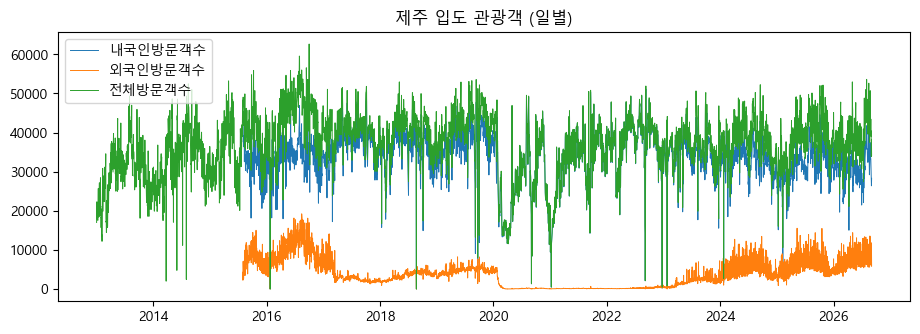

In [8]:
날짜 = pd.to_datetime(table.columns, format="%Y%m%d")

fig, ax = plt.subplots()
for 그룹 in table.index:
    ax.plot(날짜, table.loc[그룹], linewidth=0.7, label=그룹)
ax.set_title("제주 입도 관광객 (일별)")
ax.legend()
plt.show()

2020년부터 2022년까지 외국인방문객수가 거의 0까지 떨어집니다. 알고리즘마다 이 구간을 다르게 봅니다. 뒤에서 확인합니다.

## 3. 모든 알고리즘이 쓰는 도구

### 3-1. `drop_missing` — 빈 값 버리기

알고리즘 6개가 전부 맨 앞에서 이 함수를 부릅니다. 숫자로 바꾸고 빈 값을 버립니다. 메우지 않습니다.

In [9]:
def drop_missing(x):
    """숫자로 바꾸고 빈 값은 버린다. 모든 알고리즘이 맨 앞에서 이걸 부른다.

    입력: 아무 Series
    출력: 숫자만 남은 Series (원래 index 유지)
    """
    x = pd.Series(x).astype(float)
    return x[~x.isna()]

1. `pd.Series(x).astype(float)` — 숫자로 바꿉니다.
2. `x[~x.isna()]` — 빈 값을 버립니다. 원래 index는 그대로 둡니다.

입도객 데이터는 초기 몇 년의 내국인과 외국인 칸이 비어 있습니다. 여기서 실제로 줄어듭니다.

In [10]:
내국인 = table.loc["내국인방문객수"]

print("버리기 전:", len(내국인))
print("버린 후  :", len(drop_missing(내국인)))
print()
print("빈 칸이 있는 날짜 앞 5개:")
print(내국인[내국인.isna()].index[:5].tolist())

버리기 전: 4993
버린 후  : 4052

빈 칸이 있는 날짜 앞 5개:
['20130101', '20130102', '20130103', '20130104', '20130105']


### 3-2. `cannot_judge` — 판정할 수 있는 계열인가

알고리즘마다 `drop_missing` 다음에 이 함수를 부릅니다. 여기서 True가 나오면 판정하지 않고 전부 정상으로 답한 뒤 끝냅니다.

In [11]:
def cannot_judge(x, min_points):
    """이 계열은 판정하지 말아야 하는가?

    두 가지 경우에 True 다.
        1) 표본이 min_points 보다 적다     — 통계량을 믿을 수 없다
        2) 값이 사실상 하나뿐이다          — 흩어진 정도가 0이라 기준을 못 만든다

    2번을 '값이 전부 같다'가 아니라 '사실상 같다'로 보는 이유:
    계산 과정에서 1e-17 같은 부동소수점 찌꺼기가 남으면, 그 찌꺼기끼리
    비교해 엉뚱한 이상치가 만들어진다.
    """
    if len(x) < min_points:
        return True
    spread = float(x.max() - x.min())
    tolerance = max(abs(float(x.median())), 1.0) * 1e-9
    return spread <= tolerance

1. `len(x) < min_points` — 표본이 모자라면 통계량을 믿을 수 없습니다. 필요한 개수는 알고리즘마다 다릅니다. `iqr` 은 4개, `stl` 은 주기의 두 배입니다.
2. `spread = x.max() - x.min()` — 값이 얼마나 흩어져 있는지 봅니다.
3. `tolerance` — 값이 전부 같은지가 아니라 사실상 같은지로 봅니다. 계산 과정에서 1e-17 같은 찌꺼기가 남으면 그 찌꺼기끼리 비교해 엉뚱한 이상치가 만들어지기 때문입니다.

In [12]:
외국인 = drop_missing(table.loc["외국인방문객수"])

print("값이 다 같은 계열:", cannot_judge(pd.Series([5.0] * 10), 4))
print("값이 세 개뿐     :", cannot_judge(pd.Series([1.0, 2.0, 3.0]), 4))
print("외국인방문객수   :", cannot_judge(외국인, 4))

값이 다 같은 계열: True
값이 세 개뿐     : True
외국인방문객수   : False


### 3-3. `standardize` — 평균에서 몇 배 떨어졌나

평균에서 표준편차 몇 배만큼 떨어졌는지 구합니다. `zscore` 와 `skew_kurtosis` 가 씁니다.

In [13]:
def standardize(x):
    """평균에서 표준편차 몇 배 떨어졌는지. (z = (값 - 평균) / 표준편차)

    평균과 표준편차는 극단값에 끌려간다는 점을 기억해 둘 것.
    값이 하나라도 튀면 평균이 올라가고 표준편차가 커져서,
    정작 그 튄 값의 z가 작아지는 일이 생긴다.
    """
    sd = x.std()
    if sd == 0 or np.isnan(sd):
        return pd.Series(0.0, index=x.index)
    return (x - x.mean()) / sd

1. 표준편차가 0이거나 계산이 안 되면 전부 0으로 돌려줍니다. 값이 다 같은 계열에서 0으로 나누는 것을 막습니다.
2. `(x - x.mean()) / sd` — 표준화합니다.

평균과 표준편차는 극단값에 끌려갑니다. 값이 하나라도 크게 튀면 평균이 올라가고 표준편차도 같이 커집니다.

In [14]:
z = standardize(외국인)

print("평균     :", round(외국인.mean(), 1))
print("표준편차 :", round(외국인.std(), 1))
print()
z.sort_values(ascending=False).head(5)

평균     : 3922.0
표준편차 : 3555.0



time
20160814    4.303755
20160815    4.175205
20160625    4.002493
20160922    3.992085
20160816    3.968457
Name: 외국인방문객수, dtype: float64

### 3-4. `mad` — 극단값에 안 끌려가는 흩어짐

MAD는 중앙값에서 떨어진 거리들의 중앙값입니다. 표준편차와 같은 역할을 하는데 극단값에 끌려가지 않습니다. 절반이 넘는 값이 무너져야 MAD가 흔들립니다.

In [15]:
def mad(x):
    """MAD(중앙값 절대편차) = 중앙값에서 떨어진 거리들의 중앙값.

    표준편차와 같은 역할(흩어진 정도)을 하지만 극단값에 끌려가지 않는다.
    절반이 넘는 값이 무너져야 MAD가 흔들린다.
    """
    return (x - x.median()).abs().median()

값 하나만 300으로 바꿔서 둘을 비교해 봅니다.

In [16]:
보통 = pd.Series([10, 12, 11, 13, 10, 12, 11, 12, 11, 10, 13])
튄것 = pd.Series([10, 12, 11, 13, 10, 12, 11, 300, 11, 10, 13])

print("표준편차:", round(보통.std(), 2), "→", round(튄것.std(), 2))
print("MAD     :", round(mad(보통), 2), "→", round(mad(튄것), 2))

표준편차: 1.12 → 87.05
MAD     : 1.0 → 1.0


표준편차는 크게 늘어나고 MAD는 그대로입니다. `zscore` 가 치우친 데이터에서 둔해지고 `modified_zscore` 는 그렇지 않은 이유입니다.

### 3-5. `robust_standardize` — 중앙값과 MAD로 표준화

`standardize` 의 평균 자리에 중앙값을, 표준편차 자리에 MAD를 넣은 것입니다.

```
z = 0.6745 × (값 − 중앙값) / MAD
```

In [17]:
def robust_standardize(x):
    """중앙값·MAD로 만든 표준화 점수. (Modified Z-Score)

        z = 0.6745 * (값 - 중앙값) / MAD

    0.6745를 곱하는 이유: 정규분포에서 MAD는 표준편차의 약 0.6745배다.
    그래서 이 상수를 곱해야 보통의 z 점수와 같은 눈금이 된다.
    """
    center = x.median()
    spread = mad(x)
    if spread == 0 or np.isnan(spread):          # 값이 거의 다 같은 계열
        mean_dev = (x - center).abs().mean()
        if mean_dev == 0 or np.isnan(mean_dev):
            return pd.Series(0.0, index=x.index)
        return (x - center) / (1.2533 * mean_dev)
    return 0.6745 * (x - center) / spread

1. MAD가 0이면 값이 거의 다 같다는 뜻입니다. 이때는 평균절대편차로 대신 나눕니다. 그것도 0이면 전부 0으로 돌려줍니다.
2. `0.6745` 를 곱하는 이유는 정규분포에서 MAD가 표준편차의 약 0.6745배이기 때문입니다. 이 값을 곱해야 보통의 z 점수와 눈금이 같아집니다.

바로 앞에서 쓴 계열로 두 표준화를 비교합니다. 300은 여덟 번째 값입니다.

In [18]:
print("standardize       :", round(standardize(튄것).iloc[7], 2))
print("robust_standardize:", round(robust_standardize(튄것).iloc[7], 2))

standardize       : 3.01
robust_standardize: 194.93


같은 값인데 점수가 크게 다릅니다. `standardize` 는 300 때문에 평균과 표준편차가 같이 커져서 정작 300의 점수가 작아집니다.

### 3-6. `make_result` 와 `empty_result` — 출력 형식

알고리즘 6개가 전부 `make_result` 로 결과를 만듭니다. 출력이 같은 모양이라 서로 바꿔 끼울 수 있습니다.

In [19]:
def make_result(x, score, flag, thresholds=None):
    """모든 알고리즘이 돌려주는 출력 형식.

    입력
        x           분석한 계열
        score       클수록 이상하다는 뜻의 숫자 (알고리즘마다 의미가 다름)
        flag        이상 여부 True/False
        thresholds  판정에 쓴 경계값 등 (설명용, 없으면 생략)

    출력: index가 시점인 표
        시점        value  score  flag
        2014-05|17  601.8   8.24  True
    """
    result = pd.DataFrame({
        "value": x,
        "score": pd.Series(score, index=x.index).round(4),
        "flag": pd.Series(flag, index=x.index).fillna(False),
    })
    result.attrs["thresholds"] = thresholds or {}
    return result

`value` 는 분석한 값, `score` 는 경계를 얼마나 넘었는지, `flag` 는 이상 여부입니다.

판정에 쓴 경계값은 표에 넣지 않고 `attrs["thresholds"]` 에 따로 담습니다. 알고리즘마다 담는 내용이 달라서 열로 만들면 모양이 안 맞기 때문입니다.

`empty_result` 는 `cannot_judge` 가 True일 때 쓰는 결과입니다. 점수는 전부 0, flag는 전부 False입니다.

In [20]:
def empty_result(x):
    """표본이 모자라 판정할 수 없을 때 돌려줄 결과. 전부 '이상 아님'."""
    return make_result(x, np.zeros(len(x)), np.zeros(len(x), dtype=bool),
                       {"note": "표본 부족으로 실행하지 않음"})

In [21]:
못판정 = empty_result(pd.Series([5.0, 5.0, 5.0]))

print(못판정)
print()
print(못판정.attrs["thresholds"])

   value  score   flag
0    5.0    0.0  False
1    5.0    0.0  False
2    5.0    0.0  False

{'note': '표본 부족으로 실행하지 않음'}


## 4. 알고리즘 여섯 개

`detection` 에는 알고리즘이 6개 있고 범주가 셋입니다. 범주마다 보는 것이 다릅니다.

| 범주 | 보는 것 | 알고리즘 |
|---|---|---|
| 극단치 | 값 자체가 큰가 | `iqr`, `iqr_log`, `zscore`, `modified_zscore` |
| 급증·급감 | 기대보다 큰가 | `stl_residual` |
| 분포 왜곡 | 분포를 쏠리게 만든 값이 무엇인가 | `skew_kurtosis` |

여섯 개를 전부 봅니다. 극단치 넷, 급증·급감 하나, 분포 왜곡 하나입니다.

### 4-1. `iqr` — 사분위 범위 밖

`iqr` 은 비율을 기반으로 이상치를 찾습니다. 25% 자리가 Q1, 75% 자리가 Q3 입니다. 이 사이가 가운데 절반입니다. 그 폭(Q3 − Q1)을 기준으로 위아래에 선을 긋고, 선 밖이면 이상으로 봅니다.

In [22]:
def iqr(x, k=1.5):
    """사분위 범위(IQR) 기반 극단치.

    Q1(25%)과 Q3(75%) 사이가 '가운데 절반'이다. 그 폭의 k배를 위아래로 더 준다.

        경계 = [Q1 - k*(Q3-Q1),  Q3 + k*(Q3-Q1)]

    k=1.5는 상자그림(box plot)의 수염과 같은 관례값이다.
    분포 모양을 가정하지 않아서 어떤 데이터에나 쓸 수 있다.

    점수: 경계 밖으로 나간 거리 ÷ 사분위 범위 (경계 안이면 0)
    """ 
    x = drop_missing(x)  #결측치 제거
    if cannot_judge(x, 4):                          # 사분위수를 구하는 최소조건을 충족하는지 확인
        return empty_result(x)

    q1, q3 = x.quantile([0.25, 0.75])
    spread = q3 - q1
    low, high = q1 - k * spread, q3 + k * spread

    flag = (x < low) | (x > high)
    scale = spread if spread > 0 else (x.std() or 1.0)   # 폭이 0이면 표준편차로 대체
    score = np.maximum(np.maximum(x - high, low - x), 0) / scale
    return make_result(x, score, flag, {"low": low, "high": high, "k": k})   
        # 이상치 판정 및 점수 계산

1. `drop_missing(x)` — 빈 칸을 버립니다.
2. `cannot_judge(x, 4)` — 값이 4개보다 적으면 판정하지 않고 전부 정상으로 답합니다.
3. `x.quantile([0.25, 0.75])` — Q1, Q3
4. `low, high` — 경계. `k` 가 선을 얼마나 멀리 그을지 정합니다. 기본값 1.5
5. `flag` — 경계 밖이면 True
6. `score` — 경계를 얼마나 넘었는지. 경계 안이면 0

In [23]:
x = pd.Series([10, 12, 11, 13, 10, 12, 11, 300, 12, 11, 10, 13])
result = run("iqr", x)
result

,value,score,flag
0,10.0,0.0000,False
1,12.0,0.0000,False
2,11.0,0.0000,False
3,13.0,0.0000,False
4,10.0,0.0000,False
5,12.0,0.0000,False
6,11.0,0.0000,False
7,300.0,190.3333,True
8,12.0,0.0000,False
9,11.0,0.0000,False


Q1은 10.75, Q3는 12.25, 폭은 1.5 입니다.

```
low  = 10.75 − 1.5 × 1.5 = 8.5
high = 12.25 + 1.5 × 1.5 = 14.5
```

300만 경계 밖입니다. 점수는 `(300 − 14.5) ÷ 1.5 = 190.3333` 으로, 폭의 190배만큼 넘었다는 뜻입니다.

In [24]:
result.attrs["thresholds"]

{'low': 8.5, 'high': 14.5, 'k': 1.5}

점수 계산에 `np.maximum` 이 두 번 겹쳐 있습니다.

```python
score = np.maximum(np.maximum(x - high, low - x), 0) / scale
```

안쪽은 위로 넘은 거리와 아래로 넘은 거리 중 큰 쪽입니다. 경계 안이면 둘 다 음수라 바깥 `maximum` 이 0으로 만듭니다.

In [25]:
iqr_결과 = run("iqr", 외국인)

print("경계:", iqr_결과.attrs["thresholds"])
print("탐지:", int(iqr_결과["flag"].sum()), "건")
iqr_결과[iqr_결과["flag"]].head()

경계: {'low': -7409.5, 'high': 13496.5, 'k': 1.5}
탐지: 59 건


,value,score,flag
time,,,
20151004,14464.0,0.1851,True
20151017,13594.0,0.0187,True
20151025,15012.0,0.2900,True
20160405,13787.0,0.0556,True
20160419,14283.0,0.1505,True


### 4-2. `zscore` — 평균에서 표준편차 3배 밖

평균과 표준편차로 경계를 긋습니다. 표준화한 값의 절대값이 `k`(기본 3)보다 크면 이상입니다.

In [26]:
def zscore(x, k=3.0):
    """Z-Score 기반 극단치. 정규분포를 전제한다.

        z = (값 - 평균) / 표준편차,   |z| > k 이면 이상

    정규분포라면 |z|>3 인 값은 1000개 중 3개꼴이다. 그래서 k=3이 관례다.
    다만 평균과 표준편차 자체가 극단값에 오염되므로, 분포가 치우친
    데이터에서는 둔감해진다(진짜 이상치를 놓친다).

    점수: |z|
    """
    x = drop_missing(x)   #결측치 제거
    if cannot_judge(x, 5):   # 최소조건 확인, 표본 5개 이상
        return empty_result(x)

    z = standardize(x)
    mean, sd = x.mean(), x.std()
    return make_result(x, z.abs(), z.abs() > k,
                       {"mean": mean, "std": sd,
                        "low": mean - k * sd, "high": mean + k * sd})
                    # 이상치 판정 및 점수 계산

1. `cannot_judge(x, 5)` — 값이 5개보다 적으면 판정하지 않습니다.
2. `standardize(x)` — 표준화합니다.
3. `z.abs() > k` — 절대값이 3을 넘으면 이상입니다.
4. 점수는 `|z|` 그대로입니다.

앞의 `iqr` 과 같은 12개 값에 넣어 봅니다.

In [27]:
run("zscore", x)

,value,score,flag
0,10.0,0.3050,False
1,12.0,0.2810,False
2,11.0,0.2930,False
3,13.0,0.2690,False
4,10.0,0.3050,False
5,12.0,0.2810,False
6,11.0,0.2930,False
7,300.0,3.1752,True
8,12.0,0.2810,False
9,11.0,0.2930,False


300이 잡히기는 하지만 점수가 `iqr` 보다 훨씬 작습니다. 300 때문에 평균이 올라가고 표준편차도 같이 커져서, 정작 300의 표준화 값이 작아졌기 때문입니다.

`iqr` 은 Q1과 Q3만 보므로 300 하나가 경계를 넓히지 못합니다. 같은 값인데 두 알고리즘의 점수 차이가 크게 나는 이유입니다.

In [28]:
zscore_결과 = run("zscore", 외국인)

print("경계:", zscore_결과.attrs["thresholds"])
print("탐지:", int(zscore_결과["flag"].sum()), "건")
zscore_결과[zscore_결과["flag"]].head()

경계: {'mean': np.float64(3921.9590325765053), 'std': 3555.0445282621013, 'low': np.float64(-6743.174552209799), 'high': np.float64(14587.09261736281)}
탐지: 30 건


,value,score,flag
time,,,
20151025,15012.0,3.1195,True
20160519,15560.0,3.2737,True
20160603,14625.0,3.0107,True
20160607,15119.0,3.1496,True
20160612,15033.0,3.1254,True


### 4-3. `iqr_log` 와 `modified_zscore` — 같은 틀의 변형

둘 다 앞의 알고리즘과 틀이 같고 한 군데만 다릅니다.

`iqr_log` 는 로그를 씌운 값에 `iqr` 을 그대로 적용합니다. 대부분 작고 일부만 아주 큰 데이터는 원래 값에서 경계를 그으면 큰 값 쪽이 통째로 잡힙니다. 로그로 큰 값을 눌러 놓고 같은 규칙을 씁니다. 음수가 있으면 로그를 못 쓰므로 그 계열은 건너뜁니다.

In [29]:
def iqr_log(x, k=1.5):
    """로그를 씌운 뒤 IQR.

    유동인구처럼 대부분 작고 일부만 아주 큰 데이터는, 원래 값에서 경계를 그으면
    큰 값 쪽 꼬리가 통째로 이상이 된다. log1p(x) = log(1+x) 로 큰 값을 눌러
    분포를 대칭에 가깝게 만든 뒤 같은 규칙을 적용한다.

    log1p 를 쓰는 이유: 값이 0이어도 계산된다(log(1+0)=0).
    음수가 있으면 로그를 못 쓰므로 그 계열은 건너뛴다.
    """
    x = drop_missing(x)  #결측치 제거
    if cannot_judge(x, 4) or (x < 0).any(): #최소조건 만족하는지 확인 + 음수 없는지 확인
        return empty_result(x)

    logged = np.log1p(x)                            # 여기서만 로그로 값이 바뀜
    result = iqr(logged, k)                         # 로그 변환된 값 입력
    result["value"] = x                             # 보고는 원래 값으로
    return result

`modified_zscore` 는 `zscore` 의 평균·표준편차 자리에 중앙값·MAD를 넣은 것입니다. 3-5에서 본 `robust_standardize` 를 그대로 씁니다.

In [30]:
def modified_zscore(x, k=3.5):
    """중앙값·MAD 기반 극단치. Z-Score의 강건한 형태.

        z = 0.6745 * (값 - 중앙값) / MAD,   |z| > k 이면 이상

    평균 대신 중앙값, 표준편차 대신 MAD를 쓴다. 둘 다 극단값에 끌려가지 않아서
    "이상치가 경계를 넓혀 자기를 숨기는" 문제가 생기지 않는다.
    k=3.5는 이 방식에서 널리 쓰는 관례값이다.

    점수: |z|
    """
    x = drop_missing(x)
    if cannot_judge(x, 5):
        return empty_result(x)

    z = robust_standardize(x)
    center, spread = x.median(), mad(x)
    half_width = k * spread / 0.6745 if spread else np.nan   # 경계를 원래 단위로
    return make_result(x, z.abs(), z.abs() > k,
                       {"median": center, "mad": spread,
                        "low": center - half_width, "high": center + half_width})

In [31]:
iqrlog_결과 = run("iqr_log", 외국인)
mzscore_결과 = run("mzscore", 외국인)

print("iqr_log 탐지:", int(iqrlog_결과["flag"].sum()), "건")
print("        경계:", iqrlog_결과.attrs["thresholds"])
print()
print("mzscore 탐지:", int(mzscore_결과["flag"].sum()), "건")
print("        경계:", mzscore_결과.attrs["thresholds"])

iqr_log 탐지: 4 건
        경계: {'low': 2.2055364189715814, 'high': 12.501928424154263, 'k': 1.5}

mzscore 탐지: 13 건
        경계: {'median': 3397.0, 'mad': 2602.5, 'low': -10107.447739065976, 'high': 16901.447739065974}


`iqr_log` 의 경계값은 로그를 씌운 공간의 숫자라 원래 단위가 아닙니다. 표에 나오는 `value` 만 원래 값으로 되돌려 놓습니다.

### 4-4. `stl_residual` — 기대보다 큰가

앞의 둘은 값 자체가 큰지를 봅니다. 이 알고리즘은 기대보다 큰지를 봅니다. 새벽 2시의 유동인구 50은 큰 값이 아니지만 평소 새벽이 5라면 이상입니다.

기대값은 STL 분해로 만듭니다. 계열을 추세와 주기로 설명하고, 설명되지 않고 남은 부분(잔차)이 크면 이상으로 봅니다.

```
관측값 = 추세 + 주기 + 잔차
```

In [32]:
def stl_residual(x, period=24, k=3.0):
    """STL 계절분해의 잔차로 급증·급감을 찾는다.

    STL은 계열을 세 조각으로 나눈다.

        관측값 = 추세 + 주기 + 잔차

    추세는 길게 보는 흐름, 주기는 반복되는 무늬(24시간·7일),
    잔차는 그 둘로 설명되지 않는 나머지다. 설명되지 않는 부분이 크면 이상이다.

    로그를 먼저 씌우는 이유:
        유동인구는 수준이 커지면 출렁임도 같이 커진다(성수기엔 변동 폭도 큼).
        그대로 분해하면 성수기의 정상적인 큰 출렁임이 전부 잔차에 남는다.
        로그 공간에서 분해하면 잔차가 '기대의 몇 배'라는 비율이 되어
        규모가 다른 시기를 같은 잣대로 볼 수 있다.

    주기를 두 번 이상 관측해야 분해가 된다(예: 주기 24면 최소 48시점).
    """
    x = drop_missing(x)                                                 # 결측치 제거
    if cannot_judge(x, 2 * period):                                     # 주기성이 있는 데이터 최소 2개가 있는지 확인
        return empty_result(x)

    from statsmodels.tsa.seasonal import STL

    # 1단계 — 로그 공간으로 옮긴다 (값이 0이어도 되도록 log1p)
    logged = pd.Series(np.log1p(x.to_numpy()))                          # 관측값을 로그 변환

    # 2단계 — 추세·주기·잔차로 쪼갠다 (robust=True: 이상치에 덜 끌려가게)
    decomposed = STL(logged, period=period, robust=True).fit()
    resid = pd.Series(np.asarray(decomposed.resid), index=x.index)

    # 3단계 — 잔차가 평소 잔차보다 얼마나 큰지 재고 판정
    z = robust_standardize(resid)
    return make_result(x, z.abs(), z.abs() > k,
                       {"period": period, "k": k, "space": "log1p"})   
        ## 원본 시계열 값, 이상 점수($\vert{}Z\vert{}$), 이상 여부 dataframe 형태로 정리하여 반환

1. `cannot_judge(x, 2 * period)` — 주기를 두 번은 봐야 분해가 됩니다. period가 7이면 최소 14일입니다.
2. `np.log1p(x)` — 로그 공간으로 옮깁니다. 수준이 커지면 출렁임도 같이 커지는 데이터를 같은 잣대로 보기 위해서입니다. `log1p` 는 `log(1+x)` 라서 값이 0이어도 계산됩니다.
3. `STL(logged, period=period, robust=True).fit()` — 세 조각으로 나눕니다. `robust=True` 는 이상치에 덜 끌려가게 합니다.
4. `robust_standardize(resid)` — 잔차가 평소 잔차보다 얼마나 큰지 잽니다. 여기서는 평균이 아니라 중앙값과 MAD를 씁니다.
5. `|z| > k`(기본 3)이면 이상입니다.

함수 안에서 일어나는 분해를 직접 꺼내 보면 이렇게 생겼습니다.

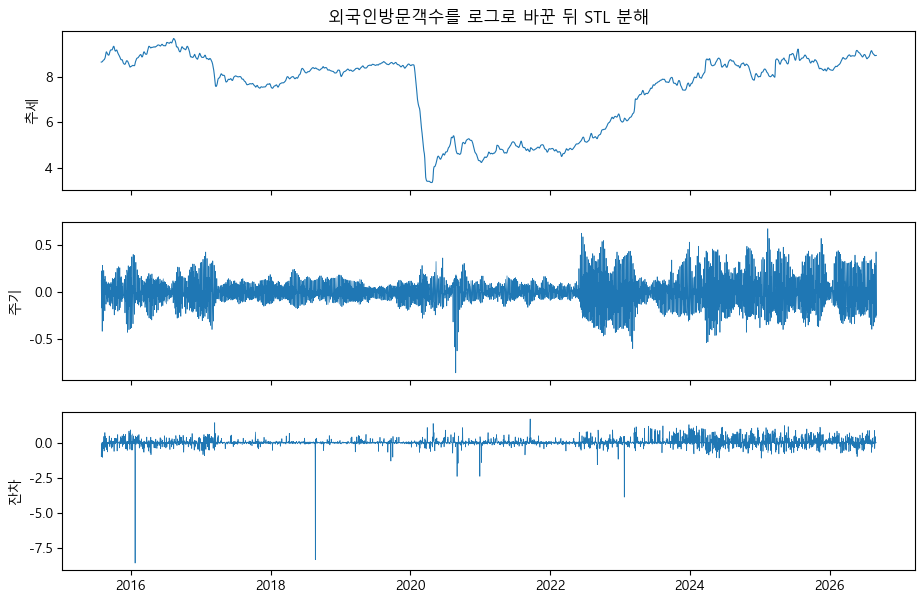

In [33]:
from statsmodels.tsa.seasonal import STL

logged = pd.Series(np.log1p(외국인.to_numpy()))
분해 = STL(logged, period=info["period"], robust=True).fit()

외국인_날짜 = pd.to_datetime(외국인.index, format="%Y%m%d")

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(외국인_날짜, 분해.trend, linewidth=0.8)
axes[0].set_ylabel("추세")
axes[1].plot(외국인_날짜, 분해.seasonal, linewidth=0.5)
axes[1].set_ylabel("주기")
axes[2].plot(외국인_날짜, 분해.resid, linewidth=0.5)
axes[2].set_ylabel("잔차")
axes[0].set_title("외국인방문객수를 로그로 바꾼 뒤 STL 분해")
plt.show()

추세는 길게 보는 흐름입니다. 2020년에 크게 떨어졌다가 2023년부터 올라옵니다.

주기는 일주일 단위로 반복되는 무늬입니다. 전체 기간 내내 모양이 거의 같습니다.

잔차는 이 둘로 설명되지 않은 나머지입니다. 2020년 초처럼 갑자기 변한 구간에서 크게 튑니다. `stl_residual` 은 이 잔차를 보고 판정합니다.

In [34]:
stl_결과 = run("stl", 외국인, period=info["period"])

print("설정:", stl_결과.attrs["thresholds"])
print("탐지:", int(stl_결과["flag"].sum()), "건")
stl_결과[stl_결과["flag"]].head()

설정: {'period': 7, 'k': 3.0, 'space': 'log1p'}
탐지: 813 건


,value,score,flag
time,,,
20150731,2374.0,14.8283,True
20150802,2288.0,15.0195,True
20150806,2700.0,15.6340,True
20150811,3627.0,6.0236,True
20150814,9949.0,6.6767,True


### 4-5. `skew_kurtosis` — 분포를 쏠리게 만든 값

앞의 셋과 질문이 다릅니다. "이 값이 이상한가"가 아니라 "이 분포를 쏠리게 만든 값이 무엇인가"를 묻습니다.

왜도는 표준화한 값의 세제곱 평균이고, 첨도는 네제곱 평균입니다. 세제곱과 네제곱을 하면 멀리 있는 값일수록 기여가 크게 불어납니다. 그래서 합에서 각 관측치가 차지하는 몫을 보면 어느 값이 분포를 쏠리게 만들었는지 알 수 있습니다.

In [35]:
def skew_kurtosis(x, share_limit=0.01):
    """분포 왜곡을 만드는 관측치를 찾는다.

    share_limit=0.01 은 "한 점이 왜도의 1% 넘게 만들었으면 지목"이라는 뜻이다.
    관측치가 n개면 평균 기여도는 1/n 이다. 1000개짜리 계열에서 평균은 0.1%이므로
    1%는 평균의 10배를 뜻한다.

    점수: 기여도 ÷ 임계 (1을 넘으면 이상)
    """
    x = drop_missing(x)
    if cannot_judge(x, 20):                     # 너무 적으면 왜도가 불안정
        return empty_result(x)

    z = standardize(x)

    # 1단계 — 분포 전체의 모양을 잰다 (설명용 숫자)
    skew = float(stats.skew(x))
    excess_kurtosis = float(stats.kurtosis(x))   # 정규분포면 0이 되도록 3을 뺀 값
    normality_p = float(stats.jarque_bera(x).pvalue)   # 0.05 미만이면 정규분포 아님

    # 2단계 — 각 관측치가 왜도/첨도에 얼마나 기여했는지 몫을 구한다
    cubed = z ** 3
    quartic = z ** 4
    skew_share = cubed.abs() / max(cubed.abs().sum(), 1e-12)
    kurtosis_share = quartic / max(quartic.sum(), 1e-12)
    share = np.maximum(skew_share, kurtosis_share)      # 둘 중 큰 쪽으로 판단

    flag = share > share_limit
    return make_result(x, share / share_limit, flag,
                       {"skew": round(skew, 3),
                        "excess_kurtosis": round(excess_kurtosis, 3),
                        "normality_p": round(normality_p, 5),
                        "mean_share": round(1 / len(x), 5),
                        "share_limit": share_limit})

1. `cannot_judge(x, 20)` — 값이 20개보다 적으면 왜도가 불안정해서 판정하지 않습니다.
2. `stats.skew`, `stats.kurtosis`, `stats.jarque_bera` — 분포 전체의 모양을 재는 숫자입니다. 판정에는 안 쓰고 설명용으로만 담습니다.
3. `skew_share`, `kurtosis_share` — 각 관측치가 세제곱 합과 네제곱 합에서 차지하는 몫입니다.
4. `share > share_limit` — 몫이 1%를 넘으면 이상으로 봅니다. 관측치가 n개면 평균 몫은 1/n 입니다. 외국인방문객수는 빈 칸을 버리면 약 4,000개라 평균 몫이 0.025%입니다. 1%는 그 40배입니다.

In [36]:
shape_결과 = run("skewkurt", 외국인)

print("분포 정보:", shape_결과.attrs["thresholds"])
print("탐지:", int(shape_결과["flag"].sum()), "건")
shape_결과[shape_결과["flag"]].head()

분포 정보: {'skew': 1.027, 'excess_kurtosis': 0.801, 'normality_p': 0.0, 'mean_share': 0.00025, 'share_limit': 0.01}
탐지: 16 건


,value,score,flag
time,,,
20160625,18151.0,1.6673,True
20160705,17709.0,1.4696,True
20160720,16798.0,1.1180,True
20160804,17403.0,1.3434,True
20160809,17659.0,1.4483,True


### 4-6. 여섯 알고리즘을 같이 보기

같은 계열에 여섯 알고리즘을 돌린 결과를 한 그림에 올립니다.

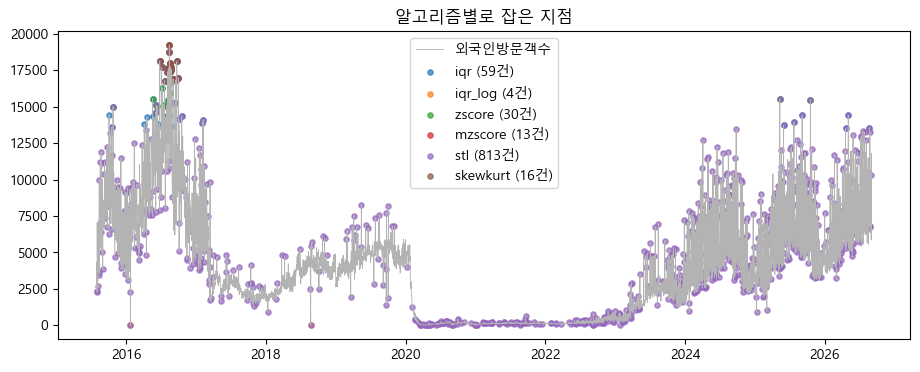

In [37]:
결과들 = {"iqr": iqr_결과, "iqr_log": iqrlog_결과,
          "zscore": zscore_결과, "mzscore": mzscore_결과,
          "stl": stl_결과, "skewkurt": shape_결과}

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(외국인_날짜, 외국인.to_numpy(), linewidth=0.6, color="0.7", label="외국인방문객수")

for i, (이름, 결과) in enumerate(결과들.items()):
    잡힌것 = 결과[결과["flag"]]
    if 잡힌것.empty:
        continue
    ax.scatter(pd.to_datetime(잡힌것.index, format="%Y%m%d"),
               잡힌것["value"], s=14, alpha=0.7, label="%s (%d건)" % (이름, len(잡힌것)))

ax.set_title("알고리즘별로 잡은 지점")
ax.legend()
plt.show()

극단치를 보는 `iqr` 과 `zscore` 는 값이 큰 쪽에 몰립니다. `stl` 은 값이 크지 않아도 기대에서 벗어나면 잡으므로 다른 자리에서도 나옵니다.

어느 쪽이 맞다고 패키지가 정하지 않습니다. 6개를 전부 돌려 CSV에 담고, 쓰는 쪽이 고릅니다.

## 5. 이름으로 부르기

### 5-1. `catalog` — 알고리즘 목록

`registry.py` 의 `ALGORITHMS` 딕셔너리가 알고리즘 목록입니다. 이름 하나로 함수를 찾을 수 있게 모아 둔 표입니다. 알고리즘을 새로 만들면 여기에 한 줄만 추가하면 됩니다.

In [38]:
def catalog():
    """알고리즘 표를 사람이 보기 좋게 돌려준다."""
    return pd.DataFrame(
        [{"name": name, "category": category, "min_points": min_points,
          "description": description}
         for name, (_, category, min_points, description) in ALGORITHMS.items()])

In [39]:
catalog()

,name,category,min_points,description
0,iqr,극단치,4,사분위 범위(Q1~Q3) 밖
1,iqr_log,극단치,4,로그를 씌운 뒤 사분위 범위 밖
2,zscore,극단치,5,평균에서 표준편차 3배 밖
3,mzscore,극단치,5,중앙값에서 MAD 3.5배 밖
4,stl,급증/급감,48,추세·주기를 걷어낸 잔차가 큼
5,skewkurt,분포 왜곡,20,왜도·첨도를 만드는 관측치


`min_points` 는 그 알고리즘이 판정하려면 값이 최소 몇 개 필요한지입니다. `stl` 이 48인 것은 period 24짜리 시간대 데이터를 기준으로 적어 둔 것이고, 실제로는 함수 안에서 `2 * period` 로 계산합니다.

### 5-2. `run` — 이름으로 알고리즘 하나 실행

앞에서 계속 쓴 `run("iqr", x)` 가 이 함수입니다.

In [40]:
def run(name, x, period=None, **options):
    """이름으로 알고리즘 하나를 돌린다.

    입력
        name     ALGORITHMS 의 키 (예: "iqr")
        x        숫자 한 줄 (pandas Series)
        period   주기. stl 처럼 필요한 알고리즘에만 쓰인다
        options  임계값 등 알고리즘별 인자 (예: k=2.0)

    출력
        DataFrame [value, score, flag]
    """
    if name not in ALGORITHMS:
        raise KeyError("모르는 알고리즘입니다: %s (가능: %s)"             # 알고리즘 이름이 없는게 들어오면 KeyError 반환
                       % (name, ", ".join(ALGORITHMS)))
    function = ALGORITHMS[name][0]
    if name in NEEDS_PERIOD and period:                                 # 주기가 있는지 검사 하고 주기가 있는 데이터이면 주기 이상탐지 알고리즘도 동작
        options.setdefault("period", period)
    return function(x, **options)                                       # 이상탐지 알고리즘 함수 실행값 반환

1. 없는 이름이면 `KeyError` 를 냅니다.
2. `ALGORITHMS[name][0]` — 딕셔너리에서 함수를 꺼냅니다.
3. `NEEDS_PERIOD` 에 들어 있는 알고리즘에만 `period` 를 넣어 줍니다. 지금은 `stl` 하나뿐입니다. `iqr` 같은 함수는 `period` 인자가 없어서 그냥 넣으면 오류가 납니다.
4. 꺼낸 함수를 실행해 결과를 돌려줍니다.

In [41]:
print("iqr 에 등록된 내용 :", ALGORITHMS["iqr"])
print("period 가 필요한 것:", NEEDS_PERIOD)

iqr 에 등록된 내용 : (<function iqr at 0x000001B3DB555B20>, '극단치', 4, '사분위 범위(Q1~Q3) 밖')
period 가 필요한 것: {'stl'}


`run` 을 거치지 않고 함수를 직접 불러도 결과는 같습니다. 이름으로 부르는 쪽은 `detect_one` 이 알고리즘을 하나씩 돌릴 때 씁니다.

In [42]:
직접 = iqr(x)
이름으로 = run("iqr", x)

print("같은 결과인가:", 직접.equals(이름으로))

같은 결과인가: True


## 6. 전부 돌리기

### 6-1. `detect_one` — 계열 하나

계열 하나에 알고리즘을 전부 돌리고, 이상으로 잡힌 지점만 모읍니다.

In [43]:
def detect_one(x, period=None, algorithms=None):
    """계열 **하나**에 모든 알고리즘을 돌린다.

    입력
        x           숫자 한 줄 (pandas Series) — 격자 하나, 지역 하나의 이력
        period      주기 (stl 에 쓰임)
        algorithms  돌릴 알고리즘 이름 목록. 없으면 전부

    출력
        DataFrame [time, value, algorithm, category, score]
        이상으로 판정된 지점만 담는다. 하나도 없으면 빈 표.
    """
    names = algorithms or list(ALGORITHMS)            # 지정한 알고리즘을 실행, 만약 지정한 알고리즘 없으면 모든 알고리즘 실행 
    pieces = []
    for name in names:
        result = run(name, x, period)
        hits = result[result["flag"]]                 # 이상인 지점만 골라낸다
        if hits.empty: 
            continue
        pieces.append(pd.DataFrame({                  # 이상탐지 지점의 시간,관측 값,알고리즘,범주,점수를 추출
            "time": hits.index,
            "value": hits["value"].to_numpy(),
            "algorithm": name,
            "category": ALGORITHMS[name][1],
            "score": hits["score"].to_numpy(),
        }))
    if not pieces:
        return pd.DataFrame(columns=COLUMNS)
    return pd.concat(pieces, ignore_index=True)      # 모든 알고리즘 이상탐지값을  하나로 합쳐서 반환

1. `names` — 지정한 알고리즘이 없으면 6개 전부입니다.
2. `run(name, x, period)` 로 알고리즘을 하나씩 돌립니다.
3. `result[result["flag"]]` — 이상인 지점만 골라냅니다.
4. 시점, 값, 알고리즘 이름, 범주, 점수를 꺼내 한 줄씩 만듭니다.
5. 알고리즘별 결과를 이어 붙여 돌려줍니다. 하나도 없으면 빈 표입니다.

같은 지점을 여러 알고리즘이 잡으면 여러 줄이 됩니다.

In [44]:
한줄 = detect_one(외국인, info["period"])

print(한줄.shape)
한줄.head(10)

(935, 5)


,time,value,algorithm,category,score
0,20151004,14464.0,iqr,극단치,0.1851
1,20151017,13594.0,iqr,극단치,0.0187
2,20151025,15012.0,iqr,극단치,0.2900
3,20160405,13787.0,iqr,극단치,0.0556
4,20160419,14283.0,iqr,극단치,0.1505
5,20160519,15560.0,iqr,극단치,0.3948
6,20160521,14339.0,iqr,극단치,0.1612
7,20160526,14289.0,iqr,극단치,0.1516
8,20160603,14625.0,iqr,극단치,0.2159
9,20160607,15119.0,iqr,극단치,0.3104


In [45]:
한줄["algorithm"].value_counts()

algorithm
stl         813
iqr          59
zscore       30
skewkurt     16
mzscore      13
iqr_log       4
Name: count, dtype: int64

### 6-2. `detect_all` — 표 전체

표의 행마다 `detect_one` 을 한 번씩 부르고 `group` 열을 붙입니다. 그게 전부입니다.

In [46]:
def detect_all(table, period=24, algorithms=None, verbose=True):
    """표의 **모든 그룹**에 모든 알고리즘을 돌린다.

    입력
        table       그룹 × 시점 DataFrame (loader 가 만든 것)
        period      주기
        algorithms  돌릴 알고리즘 이름 목록. 없으면 전부

    출력
        DataFrame [group, time, value, algorithm, category, score]
    """
    pieces = []
    step = max(len(table) // 10, 1)                   # 진행 상황을 10번만 찍는다
    for i, (group, series) in enumerate(table.iterrows(), 1):
        found = detect_one(series.dropna(), period, algorithms)   # ← 여기서 detect_one함수 재사용
        if not found.empty:
            found.insert(0, "group", group)           # 어느 그룹인지 표시
            pieces.append(found)
        if verbose and (i % step == 0 or i == len(table)):
            print("  진행 %s / %s" % (format(i, ","), format(len(table), ",")))

    if not pieces:
        return pd.DataFrame(columns=["group"] + COLUMNS)
    return pd.concat(pieces, ignore_index=True).sort_values(
        ["group", "time", "algorithm"])     # 최종적으로 [group, time, algorithm] 순으로 정렬하여 반환합니다.

1. `table.iterrows()` — 행(그룹)을 하나씩 꺼냅니다.
2. `detect_one(series.dropna(), period, algorithms)` — 그 행에 알고리즘을 전부 돌립니다.
3. `found.insert(0, "group", group)` — 어느 그룹인지 표시합니다.
4. 진행 상황을 10번만 찍습니다.
5. 전부 이어 붙이고 `group`, `time`, `algorithm` 순으로 정렬합니다.

입도객 데이터는 그룹이 3개뿐이라 금방 끝납니다. STL은 계열이 길어서 조금 걸립니다.

In [47]:
found = detect_all(table, period=info["period"])

print()
print(found.shape)
found.head(10)

  진행 1 / 3


  진행 2 / 3


  진행 3 / 3

(3436, 6)


,group,time,value,algorithm,category,score
503,내국인방문객수,20150801,43961.0,stl,급증/급감,6.3619
504,내국인방문객수,20150804,37575.0,stl,급증/급감,5.8226
505,내국인방문객수,20150807,36418.0,stl,급증/급감,5.1472
506,내국인방문객수,20150829,30012.0,stl,급증/급감,5.5408
507,내국인방문객수,20150830,30847.0,stl,급증/급감,4.8892
508,내국인방문객수,20150831,29722.0,stl,급증/급감,5.6494
509,내국인방문객수,20150915,26187.0,stl,급증/급감,4.5342
510,내국인방문객수,20150920,25482.0,stl,급증/급감,5.2944
161,내국인방문객수,20150922,21046.0,iqr_log,극단치,0.2445
511,내국인방문객수,20150922,21046.0,stl,급증/급감,10.9400


### 6-3. `summarize` — 알고리즘별 건수

탐지 건수만 보면 안 됩니다. 전체 칸 대비 비율을 같이 봐야 어느 알고리즘이 과하게 잡는지 알 수 있습니다.

In [48]:
def summarize(found, table):
    """알고리즘마다 몇 건을 찾았는지 정리한다.

    탐지 건수만 보면 안 된다. 전체 칸 대비 비율을 같이 봐야
    "이 알고리즘이 과하게 잡는가"를 알 수 있다.
    """
    total_cells = table.shape[0] * table.shape[1] # 전체 데이터셀 수 를 구함
    rows = []
    for name, (_, category, _, description) in ALGORITHMS.items():
        count = int((found["algorithm"] == name).sum()) if not found.empty else 0 #등록된 알고리즘마다 이상치로 판정한 건수(count)와 전체 대비 비중(percent)을 계산
        rows.append({"algorithm": name, "category": category, "count": count,
                     "percent": round(100 * count / total_cells, 2),
                     "description": description})
    return pd.DataFrame(rows).sort_values("count", ascending=False)  # 요약 데이터프레임을 생성

1. `total_cells` — 행 수 × 열 수. 전체 칸 수입니다.
2. 알고리즘마다 건수를 세고 전체 칸 대비 비율을 냅니다.
3. 건수가 많은 순으로 정렬합니다.

한 건도 못 찾은 알고리즘도 0으로 표에 남습니다. 돌아갔는데 0건인 것과 아예 안 돌린 것을 구분할 수 있습니다.

In [49]:
summary = summarize(found, table)
summary

,algorithm,category,count,percent,description
4,stl,급증/급감,2270,15.15,추세·주기를 걷어낸 잔차가 큼
1,iqr_log,극단치,488,3.26,로그를 씌운 뒤 사분위 범위 밖
0,iqr,극단치,378,2.52,사분위 범위(Q1~Q3) 밖
3,mzscore,극단치,138,0.92,중앙값에서 MAD 3.5배 밖
2,zscore,극단치,122,0.81,평균에서 표준편차 3배 밖
5,skewkurt,분포 왜곡,40,0.27,왜도·첨도를 만드는 관측치


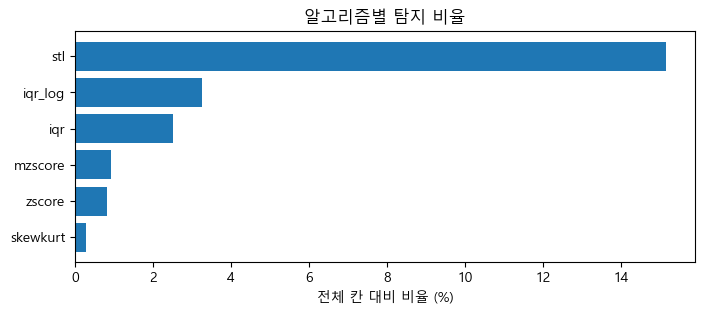

In [50]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(summary["algorithm"], summary["percent"])
ax.invert_yaxis()
ax.set_xlabel("전체 칸 대비 비율 (%)")
ax.set_title("알고리즘별 탐지 비율")
plt.show()

## 7. 결과

`save` 가 CSV 두 개로 저장합니다. 엑셀에서 한글이 깨지지 않도록 BOM을 붙입니다.

In [51]:
def save(found, summary, outdir="결과"):
    """CSV 두 개로 저장한다. 엑셀에서 한글이 깨지지 않도록 BOM을 붙인다."""
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    found.to_csv(outdir / "anomalies.csv", index=False, encoding="utf-8-sig")
    summary.to_csv(outdir / "summary.csv", index=False, encoding="utf-8-sig")
    print("\n저장")
    print("  %s" % (outdir / "anomalies.csv"))
    print("  %s" % (outdir / "summary.csv"))
    return outdir

1. `outdir.mkdir(parents=True, exist_ok=True)` — 폴더가 없으면 만듭니다. 중간 폴더까지 한 번에 만들고, 이미 있어도 오류를 내지 않습니다.
2. `encoding="utf-8-sig"` — 파일 앞에 BOM을 붙입니다. 엑셀이 이걸 보고 UTF-8로 읽어서 한글이 안 깨집니다.
3. 저장한 폴더 경로를 돌려줍니다. 바로 이어서 쓸 수 있습니다.

In [52]:
저장위치 = save(found, summary, OUT)


저장
  out\code_explain\anomalies.csv
  out\code_explain\summary.csv


`anomalies.csv` 는 이상으로 판정된 지점이 한 줄씩 들어갑니다.

| 열 | 뜻 |
|---|---|
| `group` | 분석 단위 |
| `time` | 시점 |
| `value` | 그때 관측된 값 |
| `algorithm` | 이상이라고 판정한 알고리즘 |
| `category` | 그 알고리즘이 보는 관점 |
| `score` | 판정 경계를 얼마나 넘었는지 |

`summary.csv` 는 알고리즘마다 몇 건을 찾았는지입니다.

In [53]:
pd.read_csv(저장위치 / "anomalies.csv").head()

,group,time,value,algorithm,category,score
0,내국인방문객수,20150801,43961.0,stl,급증/급감,6.3619
1,내국인방문객수,20150804,37575.0,stl,급증/급감,5.8226
2,내국인방문객수,20150807,36418.0,stl,급증/급감,5.1472
3,내국인방문객수,20150829,30012.0,stl,급증/급감,5.5408
4,내국인방문객수,20150830,30847.0,stl,급증/급감,4.8892


## 정리

- `loader.py` 가 형식이 다른 CSV를 행 = 분석 단위, 열 = 시점인 표 하나로 바꿉니다.
- 알고리즘 6개는 전부 숫자 한 줄을 받아 `[value, score, flag]` 세 칸짜리 표를 돌려줍니다. 입출력이 같아서 서로 바꿔 끼울 수 있습니다.
- `registry.py` 가 이름과 함수를 묶어 둡니다. 알고리즘을 추가하려면 여기에 한 줄만 넣으면 됩니다.
- `runner.py` 가 표의 행마다 알고리즘을 전부 돌리고 CSV 두 개로 저장합니다.
- 패키지는 어느 알고리즘이 맞는지 고르지 않습니다. 전부 돌려서 내놓고, 쓰는 쪽이 정합니다.

명령행으로도 같은 일을 할 수 있습니다. 저장소 뿌리에서 실행합니다.

```
python -m detection arrivals --pattern "data/전처리 데이터/입도 관광객 추이(일별).csv" --out result/notebook
```